# Experiment 01C : Modular Collagen Architecture

**Goal** : To create a simplified tumor ECM architecture with spatial variation while keeping every biological assumption adjustable.

This will consist of three main tissue components : 

1. Tumor-dominant tissue (Tumor-cell-rich regions), Lower relative collagen
2. Stromal regions (ECM-rich areas), Elevated relative collagen
3. Local collagen structures (Fiborous bands/aggregates), spatially localized collagen enrichment

In [21]:
import numpy as np
import matplotlib.pyplot as plt
import json

# ============================================================
# EXPERIMENT 01C — COLLAGEN ARCHITECTURE GENERATION
# ============================================================

# ----------------------------
# 1. Load shared parameters
# ----------------------------

# Load shared model parameters
with open("Parameters/model_params.json", "r") as f:
    params = json.load(f)

Lx = params["Lx"]  # cm
Ly = params["Ly"]  # cm

Nx = params["Nx"]
Ny = params["Ny"]

# Convert tissue dimensions to micrometers
Lx_um = Lx * 1e4
Ly_um = Ly * 1e4

# ----------------------------
# 2. Domain and grid
# ----------------------------

x_um = np.linspace(0, Lx_um, Nx)
y_um = np.linspace(0, Ly_um, Ny)

X, Y = np.meshgrid(x_um, y_um, indexing="ij")

# ----------------------------
# 3. Collagen parameters
# ----------------------------

rho_mean_target = params["rho_mean"]
rho_min = params["rho_min"]
rho_max = params["rho_max"]

# ----------------------------
# 4. Mean-matching function
# ----------------------------

def match_mean_bounded(field, target_mean, lower=0.0, upper=1.0):

    field = np.asarray(field, dtype=float)

    lo = -2.0
    hi = 2.0

    for _ in range(200):

        shift = (lo + hi) / 2
        candidate = np.clip(field + shift, lower, upper)

        if candidate.mean() < target_mean:
            lo = shift
        else:
            hi = shift

    shift = (lo + hi) / 2

    matched = np.clip(field + shift, lower, upper)

    return matched

In [22]:
# ============================================================
# 4. ARCHITECTURE A — UNIFORM COLLAGEN
# ============================================================

rho_uniform = np.full(
    (Nx, Ny),
    rho_mean_target,
    dtype=float
)


# ============================================================
# 5. ARCHITECTURE B — PATCHY COLLAGEN
# ============================================================

g1 = 0.80 * np.exp(
    -(
        ((X - 25.0) / 14.0) ** 2
        +
        ((Y - 70.0) / 30.0) ** 2
    ) / 2.0
)

g2 = 0.60 * np.exp(
    -(
        ((X - 75.0) / 20.0) ** 2
        +
        ((Y - 145.0) / 25.0) ** 2
    ) / 2.0
)

g3 = 0.35 * np.exp(
    -(
        ((X - 40.0) / 25.0) ** 2
        +
        ((Y - 120.0) / 18.0) ** 2
    ) / 2.0
)

patchy_raw = g1 + g2 + g3

rho_patchy = match_mean_bounded(
    patchy_raw,
    rho_mean_target,
    lower=rho_min,
    upper=rho_max
)


# ============================================================
# 6. ARCHITECTURE C — COLLAGEN BAND
# ============================================================

band_raw = (
    np.exp(
        -((X - 55)**2 / (2 * 12**2)))
    *
    (0.85 + 0.15 * np.cos(2 * np.pi * Y / Ly_um))
)

rho_band = match_mean_bounded(
    band_raw,
    rho_mean_target,
    rho_min,
    rho_max
)

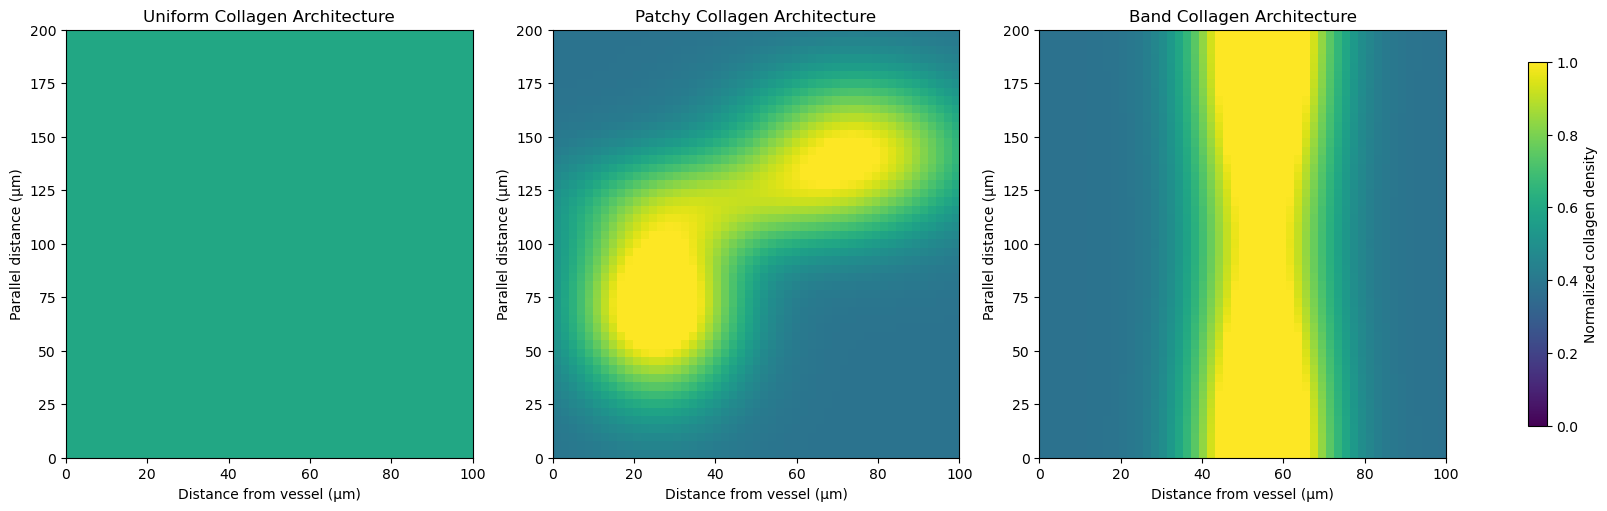

COLLAGEN ARCHITECTURE SUMMARY

Uniform
----------------------------------------
Mean:  0.600000
SD:    0.000000
CV:    0.000000
Min:   0.600000
Max:   0.600000
Shape: (51, 51)

Patchy
----------------------------------------
Mean:  0.600000
SD:    0.209897
CV:    0.349828
Min:   0.380797
Max:   1.000000
Shape: (51, 51)

Band
----------------------------------------
Mean:  0.600000
SD:    0.247733
CV:    0.412888
Min:   0.377888
Max:   1.000000
Shape: (51, 51)


In [23]:
# ============================================================
# 7. COLLECT ARCHITECTURES
# ============================================================

collagen_fields = {
    "Uniform": rho_uniform,
    "Patchy": rho_patchy,
    "Band": rho_band
}


# ============================================================
# 8. VISUALIZE COLLAGEN ARCHITECTURES
# ============================================================

fig, axes = plt.subplots(
    1, 3,
    figsize=(16, 5),
    constrained_layout=True
)

for ax, (name, field) in zip(
    axes,
    collagen_fields.items()
):

    im = ax.imshow(
        field.T,
        origin="lower",
        extent=[0, Lx_um, 0, Ly_um],
        aspect="auto",
        cmap="viridis",
        vmin=0,
        vmax=1
    )

    ax.set_title(f"{name} Collagen Architecture")
    ax.set_xlabel("Distance from vessel (µm)")
    ax.set_ylabel("Parallel distance (µm)")

fig.colorbar(
    im,
    ax=axes,
    label="Normalized collagen density",
    shrink=0.85
)

plt.show()


# ============================================================
# 9. ARCHITECTURE STATISTICS
# ============================================================

print("=" * 70)
print("COLLAGEN ARCHITECTURE SUMMARY")
print("=" * 70)

for name, field in collagen_fields.items():

    mean = field.mean()
    sd = field.std()
    cv = sd / mean if mean != 0 else np.nan

    print(f"\n{name}")
    print("-" * 40)
    print(f"Mean:  {mean:.6f}")
    print(f"SD:    {sd:.6f}")
    print(f"CV:    {cv:.6f}")
    print(f"Min:   {field.min():.6f}")
    print(f"Max:   {field.max():.6f}")
    print(f"Shape: {field.shape}")

np.savez_compressed(
    "Parameters/collagen_fields_01C.npz",
    **collagen_fields
)